# Wilson-Cowan Population Model
In this notebook, we simulate the Wilson-Cowan model of excitatory and inhibitory populations.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
%matplotlib inline

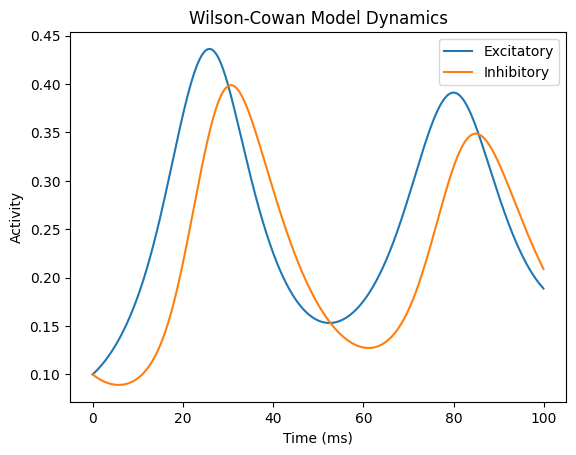

In [2]:
def sigmoid(x, a, theta):
    return 1 / (1 + np.exp(-a * (x - theta)))

# Parameters
tau_e = 10.0
tau_i = 10.0
w_ee = 12.0
w_ie = 10.0
w_ei = 10.0
w_ii = 2.0
a_e = 1.0
a_i = 1.0
theta_e = 2.0
theta_i = 3.5

dt = 0.1
t = np.arange(0, 100, dt)
E = np.zeros(len(t))
I = np.zeros(len(t))

E[0] = 0.1
I[0] = 0.1

for k in range(1, len(t)):
    dE = (-E[k-1] + sigmoid(w_ee * E[k-1] - w_ei * I[k-1], a_e, theta_e)) / tau_e
    dI = (-I[k-1] + sigmoid(w_ie * E[k-1] - w_ii * I[k-1], a_i, theta_i)) / tau_i
    E[k] = E[k-1] + dt * dE
    I[k] = I[k-1] + dt * dI

plt.plot(t, E, label='Excitatory')
plt.plot(t, I, label='Inhibitory')
plt.xlabel('Time (ms)')
plt.ylabel('Activity')
plt.title('Wilson-Cowan Model Dynamics')
plt.legend()
plt.show()